# Experiment 3: CNN on CIFAR-10

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

SEED = 42
EPOCHS = 20
BATCH_SIZE = 32
NUM_CLASSES = 10
CLASS_NAMES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

np.random.seed(SEED)
tf.random.set_seed(SEED)

## Dataset Loading

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)
print("train shape:", x_train.shape, y_train.shape)
print("test shape :", x_test.shape, y_test.shape)

train shape: (50000, 32, 32, 3) (50000,)
test shape : (10000, 32, 32, 3) (10000,)


## Sample Images

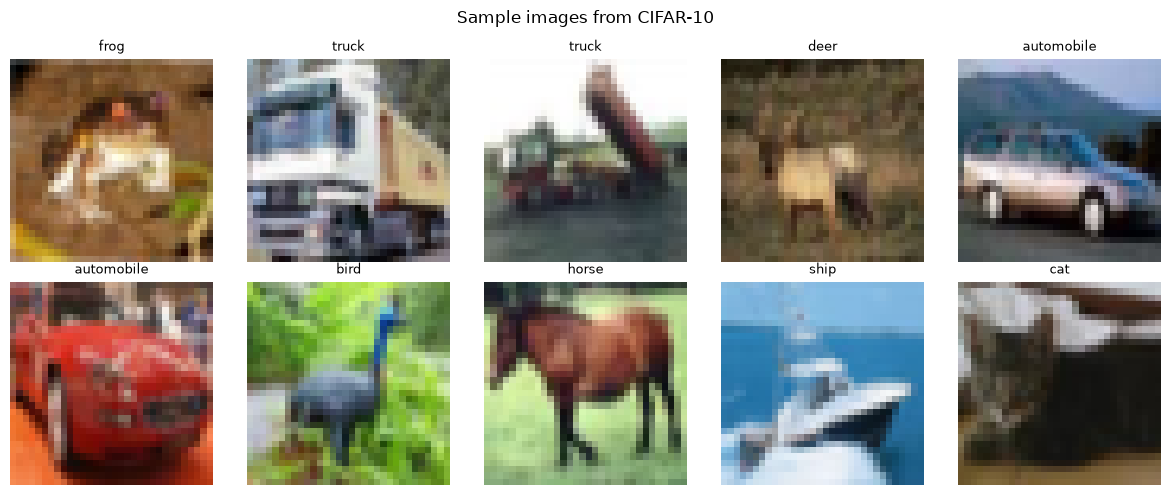

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[int(y_train[i])], fontsize=9)
    ax.axis("off")
fig.suptitle("Sample images from CIFAR-10")
plt.tight_layout()
plt.savefig("plot_01_sample_images.png", dpi=110, bbox_inches="tight")
plt.show()

## Class Distribution

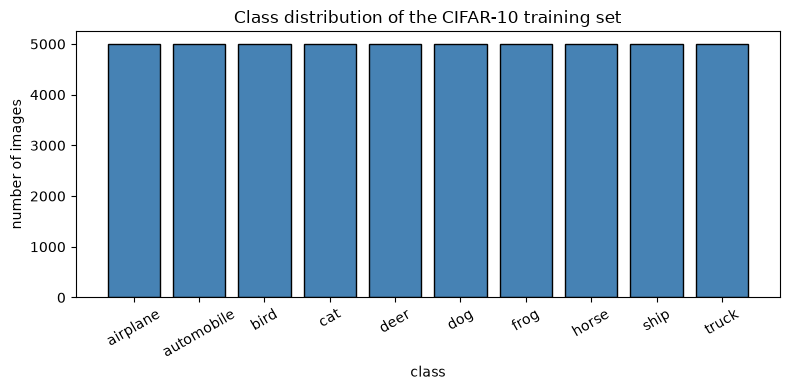

In [4]:
counts = np.bincount(y_train, minlength=NUM_CLASSES)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(CLASS_NAMES, counts, color="steelblue", edgecolor="black")
ax.set_title("Class distribution of the CIFAR-10 training set")
ax.set_xlabel("class")
ax.set_ylabel("number of images")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("plot_02_class_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

## Preprocessing

In [5]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train_one_hot = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_one_hot = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)
print("x range:", float(x_train.min()), "to", float(x_train.max()))
print("y_train_one_hot shape:", y_train_one_hot.shape)

x range: 0.0 to 1.0
y_train_one_hot shape: (50000, 10)


## Model Definition

In [6]:
def build_cnn(pooling="max"):
    Pool = tf.keras.layers.MaxPooling2D if pooling == "max" else tf.keras.layers.AveragePooling2D
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1"),
        Pool(pool_size=(2, 2), name=f"{pooling}_pool1"),
        tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2"),
        Pool(pool_size=(2, 2), name=f"{pooling}_pool2"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

def convolution_output_size(n, f, padding, stride):
    if padding == "same":
        return int(np.ceil(n / stride))
    return int(np.floor((n - f) / stride) + 1)

def evaluate_model(model, x_test, y_test, y_test_one_hot):
    probs = model.predict(x_test, verbose=0)
    preds = np.argmax(probs, axis=1)
    return {
        "accuracy": float(accuracy_score(y_test, preds)),
        "precision": float(precision_score(y_test, preds, average="macro", zero_division=0)),
        "recall": float(recall_score(y_test, preds, average="macro", zero_division=0)),
        "f1": float(f1_score(y_test, preds, average="macro", zero_division=0)),
        "confusion_matrix": confusion_matrix(y_test, preds).tolist(),
        "classification_report": classification_report(y_test, preds, target_names=CLASS_NAMES, digits=4, zero_division=0),
        "test_loss": float(model.evaluate(x_test, y_test_one_hot, verbose=0)[0]),
        "predictions": preds
    }

## Convolution Output Dimensions

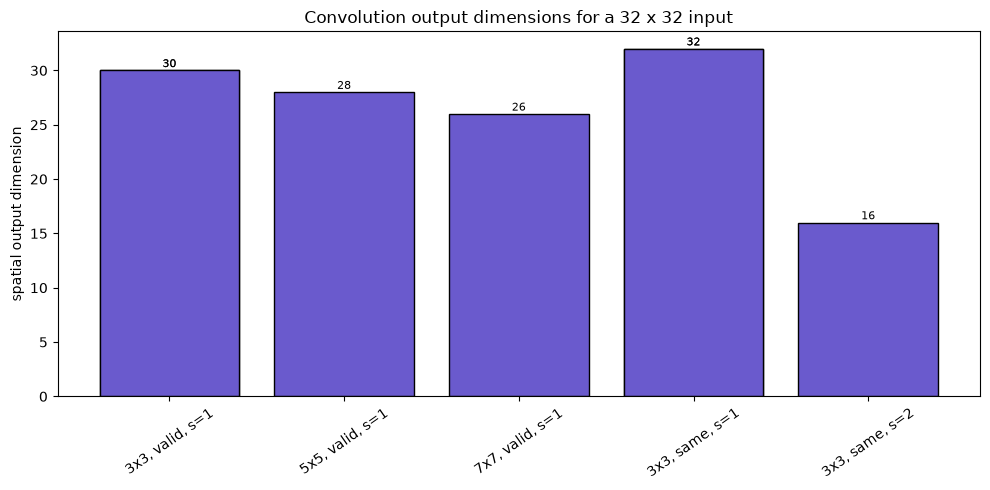

In [7]:
dimension_rows = []
for k in (3, 5, 7):
    out = convolution_output_size(32, k, "valid", 1)
    dimension_rows.append({"label": f"{k}x{k}, valid, s=1", "output": out})
for s in (1, 2):
    out = convolution_output_size(32, 3, "same", s)
    dimension_rows.append({"label": f"3x3, same, s={s}", "output": out})
for p in ("same", "valid"):
    out = convolution_output_size(32, 3, p, 1)
    dimension_rows.append({"label": f"3x3, {p}, s=1", "output": out})

labels = [r["label"] for r in dimension_rows]
values = [r["output"] for r in dimension_rows]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, values, color="slateblue", edgecolor="black")
ax.set_ylabel("spatial output dimension")
ax.set_title("Convolution output dimensions for a 32 x 32 input")
ax.tick_params(axis="x", rotation=35)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.3, str(v), ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("plot_08_convolution_output_dimensions.png", dpi=110, bbox_inches="tight")
plt.show()

## Training

In [8]:
pool_results = {}
histories = {}
models = {}

for pooling in ("max", "average"):
    print(f"Training {pooling}-pooling CNN for {EPOCHS} epochs...")
    model = build_cnn(pooling)
    model.summary()
    start = time.perf_counter()
    history = model.fit(x_train, y_train_one_hot, validation_split=0.1, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)
    elapsed = time.perf_counter() - start
    eval_res = evaluate_model(model, x_test, y_test, y_test_one_hot)
    eval_res["training_time_seconds"] = elapsed
    eval_res["parameters"] = int(model.count_params())
    pool_results[pooling + " pooling"] = eval_res
    histories[pooling] = history.history
    models[pooling] = model
    print(f"{pooling} test accuracy: {eval_res['accuracy']:.4f}")
    print(f"{pooling} training time: {elapsed:.2f}s")

Training max-pooling CNN for 20 epochs...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool1 (MaxPooling2D)        │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool2 (MaxPooling2D)        │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

... (83 outputs left out)

1407/1407 - 10s - 7ms/step - accuracy: 0.9262 - loss: 0.2064 - val_accuracy: 0.6652 - val_loss: 1.8296


Epoch 20/20


1407/1407 - 10s - 7ms/step - accuracy: 0.9312 - loss: 0.1891 - val_accuracy: 0.6622 - val_loss: 1.9317


average test accuracy: 0.6472
average training time: 199.42s


## Evaluation

In [9]:
for name, res in pool_results.items():
    print(f"=== {name} ===")
    print(f"accuracy : {res['accuracy']:.4f}")
    print(f"precision: {res['precision']:.4f}")
    print(f"recall   : {res['recall']:.4f}")
    print(f"f1       : {res['f1']:.4f}")
    print(res["classification_report"])

=== max pooling ===
accuracy : 0.6565
precision: 0.6604
recall   : 0.6565
f1       : 0.6550
              precision    recall  f1-score   support

    airplane     0.7917    0.6310    0.7023      1000
  automobile     0.7875    0.7300    0.7577      1000
        bird     0.5972    0.4700    0.5260      1000
         cat     0.4680    0.4820    0.4749      1000
        deer     0.5658    0.6280    0.5953      1000
         dog     0.5765    0.5540    0.5650      1000
        frog     0.7037    0.7150    0.7093      1000
       horse     0.6294    0.8050    0.7065      1000
        ship     0.7261    0.8270    0.7733      1000
       truck     0.7579    0.7230    0.7400      1000

    accuracy                         0.6565     10000
   macro avg     0.6604    0.6565    0.6550     10000
weighted avg     0.6604    0.6565    0.6550     10000

=== average pooling ===
accuracy : 0.6472
precision: 0.6614
recall   : 0.6472
f1       : 0.6481
              precision    recall  f1-score   support

## Training and Validation Curves

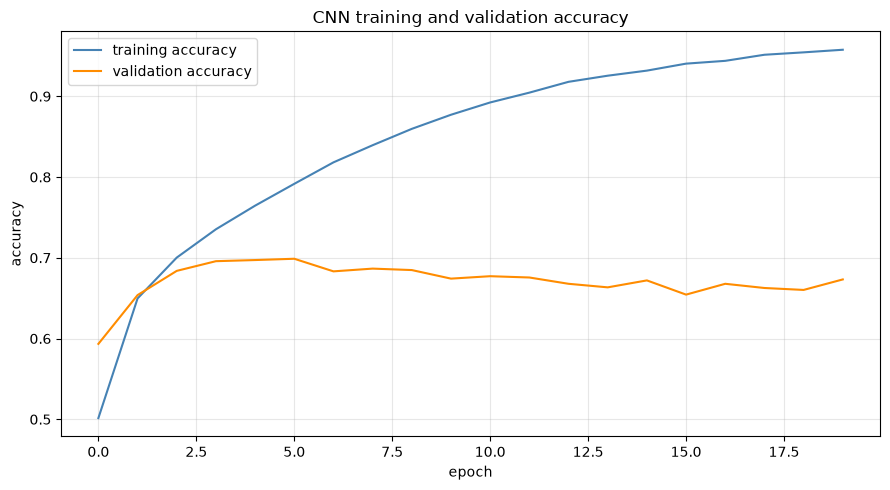

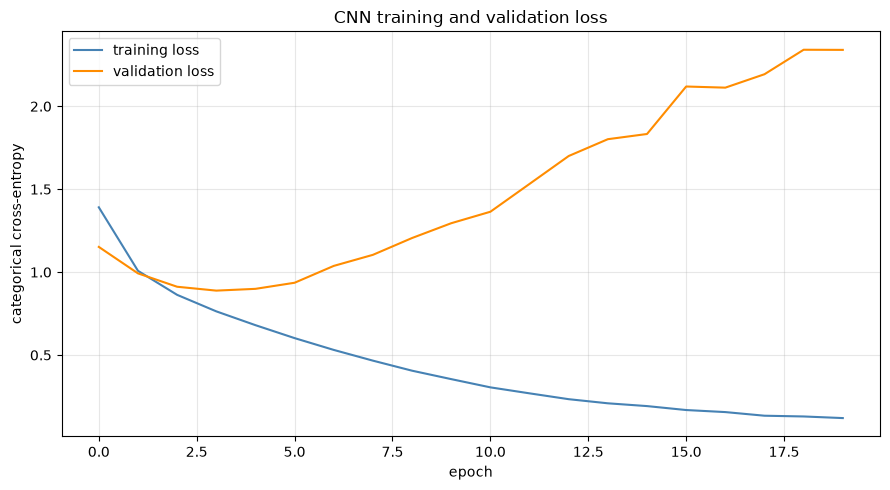

In [10]:
history = histories["max"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["accuracy"], label="training accuracy", color="steelblue")
ax.plot(history["val_accuracy"], label="validation accuracy", color="darkorange")
ax.set_title("CNN training and validation accuracy")
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_03_training_validation_accuracy.png", dpi=110, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["loss"], label="training loss", color="steelblue")
ax.plot(history["val_loss"], label="validation loss", color="darkorange")
ax.set_title("CNN training and validation loss")
ax.set_xlabel("epoch")
ax.set_ylabel("categorical cross-entropy")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_04_training_validation_loss.png", dpi=110, bbox_inches="tight")
plt.show()

## Feature Maps

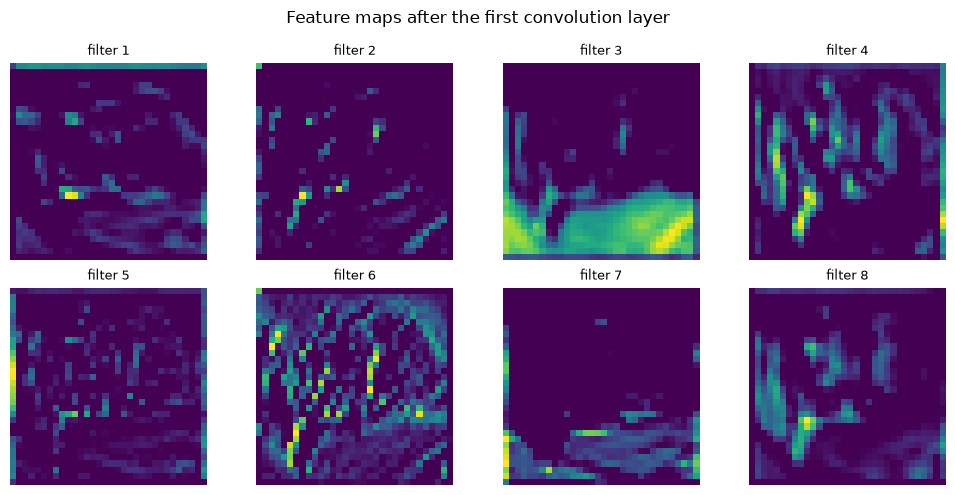

In [11]:
feature_model = tf.keras.Model(models["max"].inputs[0], models["max"].get_layer("conv1").output)
fmaps = feature_model.predict(x_test[None, 0], verbose=0)[0]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[:, :, i], cmap="viridis")
    ax.set_title(f"filter {i+1}", fontsize=9)
    ax.axis("off")
fig.suptitle("Feature maps after the first convolution layer")
plt.tight_layout()
plt.savefig("plot_05_feature_maps.png", dpi=110, bbox_inches="tight")
plt.show()

## Confusion Matrix

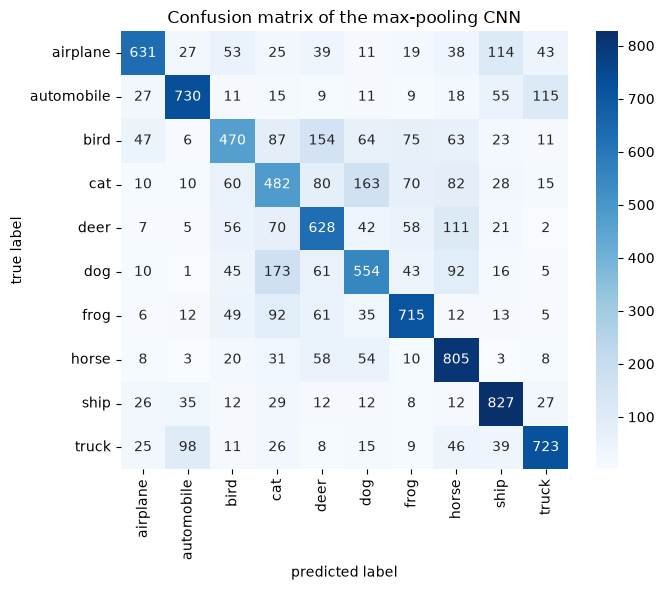

In [12]:
cm = np.asarray(pool_results["max pooling"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title("Confusion matrix of the max-pooling CNN")
ax.set_xlabel("predicted label")
ax.set_ylabel("true label")
plt.tight_layout()
plt.savefig("plot_06_confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

## Pooling Comparison

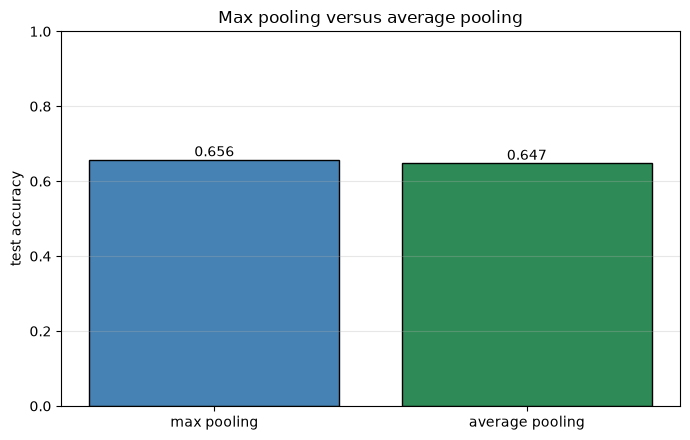

In [13]:
names = ["max pooling", "average pooling"]
accs = [pool_results[n]["accuracy"] for n in names]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(names, accs, color=["steelblue","seagreen"], edgecolor="black")
ax.set_ylim(0, 1)
ax.set_ylabel("test accuracy")
ax.set_title("Max pooling versus average pooling")
for bar, v in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.3f}", ha="center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("plot_07_pooling_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## Results Summary

In [14]:
results = {
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "max_pooling": {k: v for k, v in pool_results["max pooling"].items() if k != "predictions"},
    "average_pooling": {k: v for k, v in pool_results["average pooling"].items() if k != "predictions"},
    "dimension_rows": dimension_rows,
}
open("experiment_3_results.json","w").write(json.dumps(results, indent=2))
print(json.dumps({k: round(v["accuracy"],4) for k,v in pool_results.items()}, indent=2))

{
  "max pooling": 0.6565,
  "average pooling": 0.6472
}
